# Gallstone Dataset: Data Cleaning

**Dataset:** 319 rows × 39 columns, target = `Gallstone Status` (0/1).

**Sections**
1. Load data and overview
2. Data integrity checks (missing values, duplicates)
3. Clean column names
4. Fix data types
5. Validate value ranges (domain checks)
6. Internal consistency checks
7. Outlier detection and handling
8. Multicollinearity / redundant features
9. Class balance
10. Train/test split and feature scaling
11. Final checks and save

## 1. Load data and overview

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# ---- Set the path to your file (UCI file is usually "dataset-uci.xlsx") ----
# DATA_PATH = "dataset/dataset-uci.xlsx"
#I don't want to save another variable right now so I am using dataset directly.
df = pd.read_excel("dataset/dataset-uci.xlsx", engine="calamine")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)
print("\nDataset datatypes:")
print(df.dtypes)

Number of rows: 319
Number of columns: 39
Dataset shape: (319, 39)

Dataset datatypes:
Gallstone Status                                    int64
Age                                                 int64
Gender                                              int64
Comorbidity                                         int64
Coronary Artery Disease (CAD)                       int64
Hypothyroidism                                      int64
Hyperlipidemia                                      int64
Diabetes Mellitus (DM)                              int64
Height                                              int64
Weight                                            float64
Body Mass Index (BMI)                             float64
Total Body Water (TBW)                            float64
Extracellular Water (ECW)                         float64
Intracellular Water (ICW)                         float64
Extracellular Fluid/Total Body Water (ECF/TBW)    float64
Total Body Fat Ratio (TBFR) (%)            

In [34]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Gallstone Status,319.0,0.495298,0.500763,0.00,0.000,0.000000,1.000,1.00
Age,319.0,48.068966,12.114558,20.00,38.500,49.000000,56.000,96.00
Gender,319.0,0.492163,0.500724,0.00,0.000,0.000000,1.000,1.00
Comorbidity,319.0,0.335423,0.517340,0.00,0.000,0.000000,1.000,3.00
Coronary Artery Disease (CAD),319.0,0.037618,0.190568,0.00,0.000,0.000000,0.000,1.00
Hypothyroidism,319.0,0.028213,0.165841,0.00,0.000,0.000000,0.000,1.00
Hyperlipidemia,319.0,0.025078,0.156609,0.00,0.000,0.000000,0.000,1.00
Diabetes Mellitus (DM),319.0,0.134796,0.342042,0.00,0.000,0.000000,0.000,1.00
Height,319.0,167.156740,10.053030,145.00,159.500,168.000000,175.000,191.00
Weight,319.0,80.564890,15.709069,42.90,69.600,78.800000,91.250,143.50


## 2. Data integrity checks
### 2.1 Missing values

In [35]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_report = pd.DataFrame({"missing": missing, "missing_%": missing_pct})
print("Total missing values:", int(missing.sum()))
missing_report[missing_report["missing"] > 0]

Total missing values: 0


,missing,missing_%


### 2.2 Duplicate rows

In [36]:
n_dup = df.duplicated().sum()
print("Duplicate rows:", n_dup)
if n_dup > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("New shape after dropping duplicates:", df.shape)

Duplicate rows: 0


## 3. Clean column names
The original names contain spaces, parentheses, percent signs and a few misspellings (e.g. *Aminotransferaz*). Shorter snake_case names are easier to use in code.

In [37]:
new_names = [
    "gallstone_status", "age", "gender", "comorbidity", "cad", "hypothyroidism",
    "hyperlipidemia", "dm", "height", "weight", "bmi", "tbw", "ecw", "icw",
    "ecf_tbw", "tbfr", "lm", "protein", "vfr", "bm", "mm", "obesity", "tfc",
    "vfa", "vma", "hfa", "glucose", "tc", "ldl", "hdl", "triglyceride", "ast",
    "alt", "alp", "creatinine", "gfr", "crp", "hgb", "vitamin_d",
]
assert len(new_names) == df.shape[1], "Column count mismatch, check the list above"

# Keep a mapping for reference
name_map = dict(zip(df.columns, new_names))
df.columns = new_names
pd.Series(name_map, name="new_name").to_frame()

,new_name
Gallstone Status,gallstone_status
Age,age
Gender,gender
Comorbidity,comorbidity
Coronary Artery Disease (CAD),cad
Hypothyroidism,hypothyroidism
Hyperlipidemia,hyperlipidemia
Diabetes Mellitus (DM),dm
Height,height
Weight,weight


## 4. Fix data types
Binary / categorical columns are stored as integers. Check they only contain the expected values, then store them as `category`.

In [38]:
binary_cols = ["gallstone_status", "gender", "comorbidity", "cad",
               "hypothyroidism", "hyperlipidemia", "dm", "hfa"]

for c in binary_cols:
    print(f"{c:18s} unique values: {sorted(df[c].unique())}")

gallstone_status   unique values: [np.int64(0), np.int64(1)]
gender             unique values: [np.int64(0), np.int64(1)]
comorbidity        unique values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
cad                unique values: [np.int64(0), np.int64(1)]
hypothyroidism     unique values: [np.int64(0), np.int64(1)]
hyperlipidemia     unique values: [np.int64(0), np.int64(1)]
dm                 unique values: [np.int64(0), np.int64(1)]
hfa                unique values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [39]:
# Comorbidity may have more than 2 levels (number of comorbidities), HFA may be graded (0-4).
# Convert to category but keep the numeric codes.
for c in binary_cols:
    df[c] = df[c].astype("category")

print(df[binary_cols].dtypes)
print("\nVisceral Fat Rating (ordinal) range:", df["vfr"].min(), "to", df["vfr"].max())

gallstone_status    category
gender              category
comorbidity         category
cad                 category
hypothyroidism      category
hyperlipidemia      category
dm                  category
hfa                 category
dtype: object

Visceral Fat Rating (ordinal) range: 1 to 31


## 7. Outlier detection and handling
Use the IQR rule 
that is 
- Finds the 25th percentile (Q1) and 75th percentile (Q3).
- Computes the IQR = Q3 − Q1, the spread of the middle 50% of the data.
- Defines “fences”: anything below Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR is flagged as an outlier.
Returns a boolean Series (True = outlier, False = normal), using | to mean “or”.
We get number of rows that are outlied, percentage of entire data, skew.

In [40]:
def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

cont_cols = [c for c in df.select_dtypes(include="number").columns
             if c not in {"gallstone_status", "vfr"}]
out_counts = {c: int(iqr_outliers(df[c]).sum()) for c in cont_cols}
out_df = (pd.Series(out_counts, name="n_outliers").to_frame()
          .assign(pct=lambda d: (d["n_outliers"] / len(df) * 100).round(1),
                  skew=df[cont_cols].skew().round(2))
          .sort_values("n_outliers", ascending=False))
out_df

,n_outliers,pct,skew
crp,34,10.7,5.41
alt,27,8.5,7.28
glucose,25,7.8,5.94
ast,23,7.2,6.99
triglyceride,20,6.3,2.79
gfr,13,4.1,-1.81
alp,12,3.8,0.80
protein,8,2.5,-0.05
tfc,7,2.2,0.81
ecf_tbw,7,2.2,-0.51


crp, alt, glucose, ast, triglyceride (skew 2.8 to 7.3, 6 to 11% outliers)

This is normal for lab data. Most people have low values, while a minority have markedly elevated ones (inflammation, liver injury, diabetes, high lipids). 

We can either now
- log-transform these columns before linear models, or
- use methods that are robust to outliers (tree-based models, rank-based tests).

But one thing is very interesting We have Obesity skew at it's mathematical ceiling. That means we must have some skew value there. Plus We have good skew at ast So let's just test them.

In [41]:
df[df["obesity"] > 100]
df["obesity"].nlargest(10)

239    1954.00
23      125.60
209     106.30
280      96.63
246      95.64
293      85.90
200      85.80
83       83.10
258      80.82
90       80.80
Name: obesity, dtype: float64

In [42]:
rows = [239, 23, 209, 280, 246, 293, 200, 83, 258, 90]
df.loc[rows, ["obesity", "bmi", "weight", "height", "tbfr"]]

,obesity,bmi,weight,height,tbfr
239,1954.00,29.3,65.9,150,32.63
23,125.60,49.7,143.5,170,42.30
209,106.30,45.4,102.1,150,46.70
280,96.63,48.2,108.4,150,50.92
246,95.64,47.9,125.8,162,49.68
293,85.90,40.9,121.0,172,36.90
200,85.80,40.9,104.6,160,34.20
83,83.10,40.3,100.5,158,49.80
258,80.82,44.3,109.2,157,46.15
90,80.80,39.7,104.3,162,43.60


In [43]:
df.loc[239, "obesity"] = 19.54

This helps us know what obesity is given by: 
obesity = (weight / (standard BMI × height²) − 1) × 100
so our outliter obesity is actually 19.54 and not 1954 

In [44]:
df["hdl"].describe()
df["hdl"].nlargest(10)
df["hdl"].nsmallest(5)

24     25.0
265    25.0
26     26.0
27     26.0
223    26.0
Name: hdl, dtype: float64

In [45]:
suspects = df["hdl"].nlargest(5).index

check = df.loc[suspects, ["hdl", "tc", "ldl", "triglyceride"]].copy()
check["hdl_implied"] = check["tc"] - check["ldl"] - check["triglyceride"] / 5
check["diff"] = (check["hdl"] - check["hdl_implied"]).round(1)
check

,hdl,tc,ldl,triglyceride,hdl_implied,diff
318,273.0,296.0,155.0,19.0,137.2,135.8
258,93.0,217.0,114.0,69.0,89.2,3.8
150,89.0,212.0,105.0,50.0,97.0,-8.0
292,86.0,151.0,55.0,49.0,86.2,-0.2
184,82.0,319.0,204.0,181.0,78.8,3.2


SO our hdl at 273.0 has an error.

In [46]:
df.loc[318, ["hdl", "tc", "ldl", "triglyceride", "bmi", "age"]]
df.drop(index=318, inplace=True)

C:\Users\Hameed Computers\AppData\Local\Temp\ipykernel_20428\18865105.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(index=318, inplace=True)


This confirms it but we cannot substitute hdl like We did for Obesity. 

## 8. Multicollinearity / redundant features
Many body-composition variables measure nearly the same thing (weight, BMI, TBW, ICW, muscle mass, lean mass, fat content, obesity %).

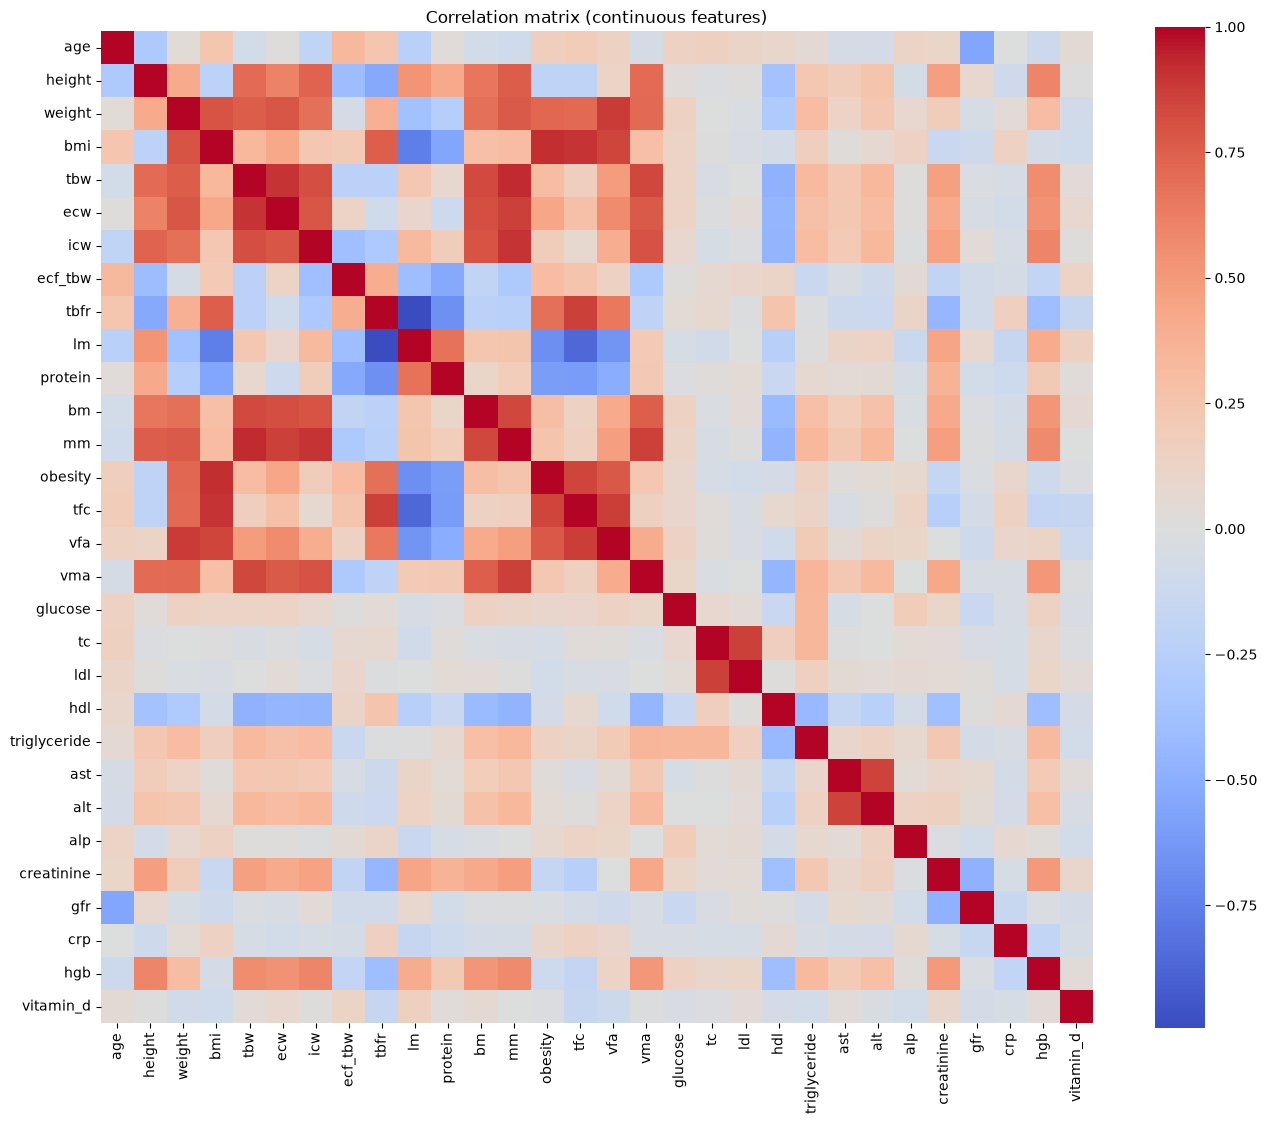

In [47]:
num = df[cont_cols]
corr = num.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True)
plt.title("Correlation matrix (continuous features)")
plt.show()

In [48]:
# 1) Pairs with |r| > 0.9 (for inspection)
upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = (upper.stack().rename("r").reset_index()
         .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
high_pairs = pairs[pairs["r"] > 0.9].sort_values("r", ascending=False)
print(high_pairs)

# 2) Drop every column that is highly correlated with an EARLIER column
to_drop = [c for c in upper.columns if (upper[c] > 0.9).any()]
print(f"Dropped {len(to_drop)}:", to_drop)

df.drop(columns=to_drop, inplace=True)

    feature_1 feature_2         r
249      tbfr        lm  0.994052
132       tbw        mm  0.928289
103       bmi   obesity  0.917637
125       tbw       ecw  0.904057
192       icw        mm  0.903617
104       bmi       tfc  0.902664
Dropped 5: ['ecw', 'lm', 'mm', 'obesity', 'tfc']


C:\Users\Hameed Computers\AppData\Local\Temp\ipykernel_20428\3081293980.py:12: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=to_drop, inplace=True)


## 9. Class balance

gallstone_status
0    161
1    157
Name: count, dtype: int64
gallstone_status
0    50.6 %
1    49.4 %
Name: count, dtype: str


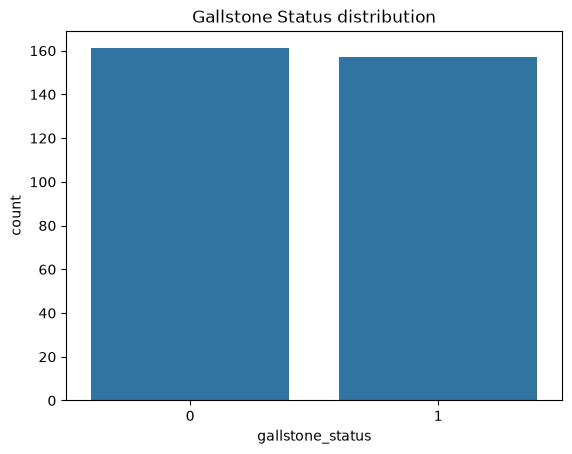

In [49]:
counts = df["gallstone_status"].value_counts().sort_index()
print(counts)
print((counts / counts.sum() * 100).round(1).astype(str) + " %")

sns.countplot(x="gallstone_status", data=df)
plt.title("Gallstone Status distribution")
plt.show()

## 10. Save cleaned data

In [50]:
output_path = "dataset/gallstone_cleaned.csv"
df.to_csv(output_path, index=False)
print(f"Cleaned data saved to {output_path}")

Cleaned data saved to dataset/gallstone_cleaned.csv
